# Active GLiNER: Multi-label classification

The task: give a text all the labels that apply, or none. For example, a sentence about tumour cells that escape the immune system gets `avoiding immune destruction`.

This notebook follows the recipe from the paper:

```
your unlabelled texts
   │  1. the untrained student ranks them once, least sure first
   ▼
top N texts ──> a random quarter: human labels
           └──> the rest: LLM labels
   │  2. train the student on both (LoRA)
   ▼
a small, fast model you own ──> 3. check it on labelled dev data ──> 4. predict
```

Data: Hallmarks of Cancer: sentences from cancer papers, 10 hallmarks; many sentences have none. The "human" labels here come from the dataset's own annotators, so you
can see the recipe end to end without labelling anything yourself.

You need a GPU (8 GB is enough) and an OpenAI-compatible LLM server. This repository
starts Gemma 4 12B with `scripts/serve_teacher_gemma.sh`; any other local or hosted
endpoint works too.

In [1]:
import json
from pathlib import Path

import torch
from IPython.display import Image, Markdown, display

from active_gliner import byod, data, tasks

TASK = "classification"
DATASET = "hallmarks"
TEACHER_URL = "http://127.0.0.1:8020/v1"
TEACHER_MODEL = "gemma-4-12b-qat"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 3090


## 1. Your data

The tool reads JSONL files, one text per line:

+ `texts.jsonl` - unlabelled texts (`text`, and for relations the `entities` list).
+ `dev.jsonl` - a few hundred texts with correct labels, to measure accuracy.

Here we write both from the dataset.

In [2]:
demo = Path("demo-classification")
demo.mkdir(exist_ok=True)
splits = data.load(DATASET)
names = tasks.labels(DATASET, splits)  # label code -> label name


def write(path, records, with_labels):
    rows = [byod.record_to_row(r, names, with_labels) for r in records]
    path.write_text("".join(json.dumps(row, ensure_ascii=False) + "\n" for row in rows))


write(demo / "texts.jsonl", splits["pool"][:5000], with_labels=False)
write(demo / "dev.jsonl", splits["dev"][:300], with_labels=True)
labels = ",".join(names.values())
print(len(names), "labels:", labels[:200], "...")
print(open(demo / "dev.jsonl").readline()[:300])

10 labels: activating invasion and metastasis,avoiding immune destruction,cellular energetics,enabling replicative immortality,evading growth suppressors,genomic instability and mutation,inducing angiogenesis,re ...
{"id": "hallmarks:en-US:22355784_0", "text": "Electronic properties of DNA are believed to play a crucial role in many phenomena in living organisms , for example the location of DNA lesions by base excision repair ( BER ) glycosylases and the regulation of tumor-suppressor genes such as p53 by dete


## 2. What the untrained student does

GLiNER2.5 already works for any label names, with no training. This is the score to beat.

In [3]:
task = tasks.for_dataset(DATASET)
dev = byod.read_labelled(demo / "dev.jsonl", TASK)
label_map = byod.parse_labels(labels)
student = byod.load_student(TASK, label_map)
zero_shot_f1 = task.score(dev, task.predict(student, dev, label_map), label_map)["micro"]["f1"]
print(f"Zero-shot dev F1: {100 * zero_shot_f1:.1f}")
del student
torch.cuda.empty_cache()

Zero-shot dev F1: 21.0


## 3. Rank once and split between humans and the LLM

`rank` scores every text with the untrained student, takes the 1,000 it is least sure
about (texts where it finds nothing go last), and puts a random quarter of them in
`for_humans.jsonl`. The rest goes in `for_llm.jsonl`.

From a terminal:

```bash
active-gliner rank --texts demo/texts.jsonl --task classification --labels "..." \
  --n 1000 --human-share 0.25 --out demo/rank
```

In [4]:
ranked = byod.rank(
    demo / "texts.jsonl", TASK, labels, n=1000, human_share=0.25, out_dir=demo / "rank"
)
for_humans = [json.loads(line) for line in (ranked / "for_humans.jsonl").open()]
for_llm = [json.loads(line) for line in (ranked / "for_llm.jsonl").open()]
print(len(for_humans), "texts for humans,", len(for_llm), "for the LLM")
print("example for a human:", for_humans[0]["text"][:200])

250 texts for humans, 750 for the LLM
example for a human: Based on a genome-wide sequencing study that identified mutations in several breast cancer genes , we examined some of the genes for mutations , expression levels , and functional effects on cell prol


## 4. Human labels

In real use, people label `for_humans.jsonl` by hand, in the same format as `dev.jsonl`.
Here we copy the dataset's own labels for those texts.

In [5]:
by_id = {r.id: r for r in splits["pool"]}
write(demo / "human.jsonl", [by_id[row["id"]] for row in for_humans], with_labels=True)
print(open(demo / "human.jsonl").readline()[:300])

{"id": "hallmarks:en-US:22341523_2", "text": "Based on a genome-wide sequencing study that identified mutations in several breast cancer genes , we examined some of the genes for mutations , expression levels , and functional effects on cell proliferation and tumorigenesis .", "labels": []}



## 5. LLM labels for the rest, then train

`fit` sends every text in `for_llm.jsonl` to the LLM (`select="all"`), checks every
answer (valid JSON, allowed labels, exact text spans), adds the human-labelled texts,
and trains a LoRA adapter. The LLM never sees the human-labelled texts.

```bash
active-gliner fit --texts demo/rank/for_llm.jsonl --select all --human demo/human.jsonl \
  --task classification --labels "..." --dev demo/dev.jsonl \
  --teacher-url http://127.0.0.1:8020/v1 --teacher-model gemma-4-12b-qat --out demo/run
```

For a hosted API, also pass `api_key_env="NAME_OF_THE_KEY_VARIABLE"`.

In [6]:
run = byod.fit(
    texts=ranked / "for_llm.jsonl",
    task=TASK,
    labels=labels,
    teacher_url=TEACHER_URL,
    teacher_model=TEACHER_MODEL,
    select="all",
    human=demo / "human.jsonl",
    dev=demo / "dev.jsonl",
    out_dir=demo / "run",
)
print(run)

demo-classification/run


## 6. Check the result

Every run folder holds plain files: a one-page report, training curves, every LLM label
and every wrong prediction.

In [7]:
metrics = json.loads((run / "metrics.json").read_text())
trained_f1 = metrics["dev"]["micro"]["f1"]
print(f"Dev F1: zero-shot {100 * zero_shot_f1:.1f} -> trained {100 * trained_f1:.1f}")
print("LLM answers:", json.loads((run / "teacher_stats.json").read_text()))

Dev F1: zero-shot 21.0 -> trained 43.6
LLM answers: {'elapsed_s': 144.4287598771043, 'workers': 8, 'gpu_shared': False, 'requests': 750, 'cache_hits': 0, 'retries': 0, 'duplicate': 0, 'prompt_tokens': 210656, 'completion_tokens': 13659, 'latency_s_total': 1152.8196898458991, 'errors_by_kind': {}, 'invalid_records': 0, 'valid_rate': 1.0, 'cost_usd': 0.0}


In [8]:
display(Markdown((run / "report.md").read_text()))

# user: all, N=750, seed=1

Locale: en-US. Labels: custom. LoRA r=32, alpha=64.0, task LR=0.0004019207998187699. Augmentation: False.
Acquisition threshold: 0.5. Evaluation threshold: 0.5.

| Split | Micro F1 | Macro F1 |
| --- | ---: | ---: |
| dev | 0.4364 | 0.3680 |

Best step: 500. Stop reason: early_stopping.
Wall time: 229.57 s. Training time: 68.33 s.

| Type | Precision | Recall | F1 | Support |
| --- | ---: | ---: | ---: | ---: |
| activating invasion and metastasis | 0.6111 | 0.9167 | 0.7333 | 12 |
| avoiding immune destruction | 0.0000 | 0.0000 | 0.0000 | 3 |
| cellular energetics | 0.3846 | 0.7143 | 0.5000 | 7 |
| enabling replicative immortality | 0.6667 | 0.5000 | 0.5714 | 4 |
| evading growth suppressors | 0.0000 | 0.0000 | 0.0000 | 6 |
| genomic instability and mutation | 0.3750 | 0.3913 | 0.3830 | 23 |
| inducing angiogenesis | 0.3548 | 0.6875 | 0.4681 | 16 |
| resisting cell death | 0.3500 | 0.5385 | 0.4242 | 13 |
| sustaining proliferative signaling | 0.3333 | 0.2222 | 0.2667 | 9 |
| tumor promoting inflammation | 0.5000 | 0.2500 | 0.3333 | 4 |

[Training curves](plots/training_curves.png) · [Calibration](plots/calibration.png) · [Errors](errors.jsonl)

Extraction calibration includes emitted predictions only; low bins can be empty because of the evaluation threshold. Classification includes all label probabilities.


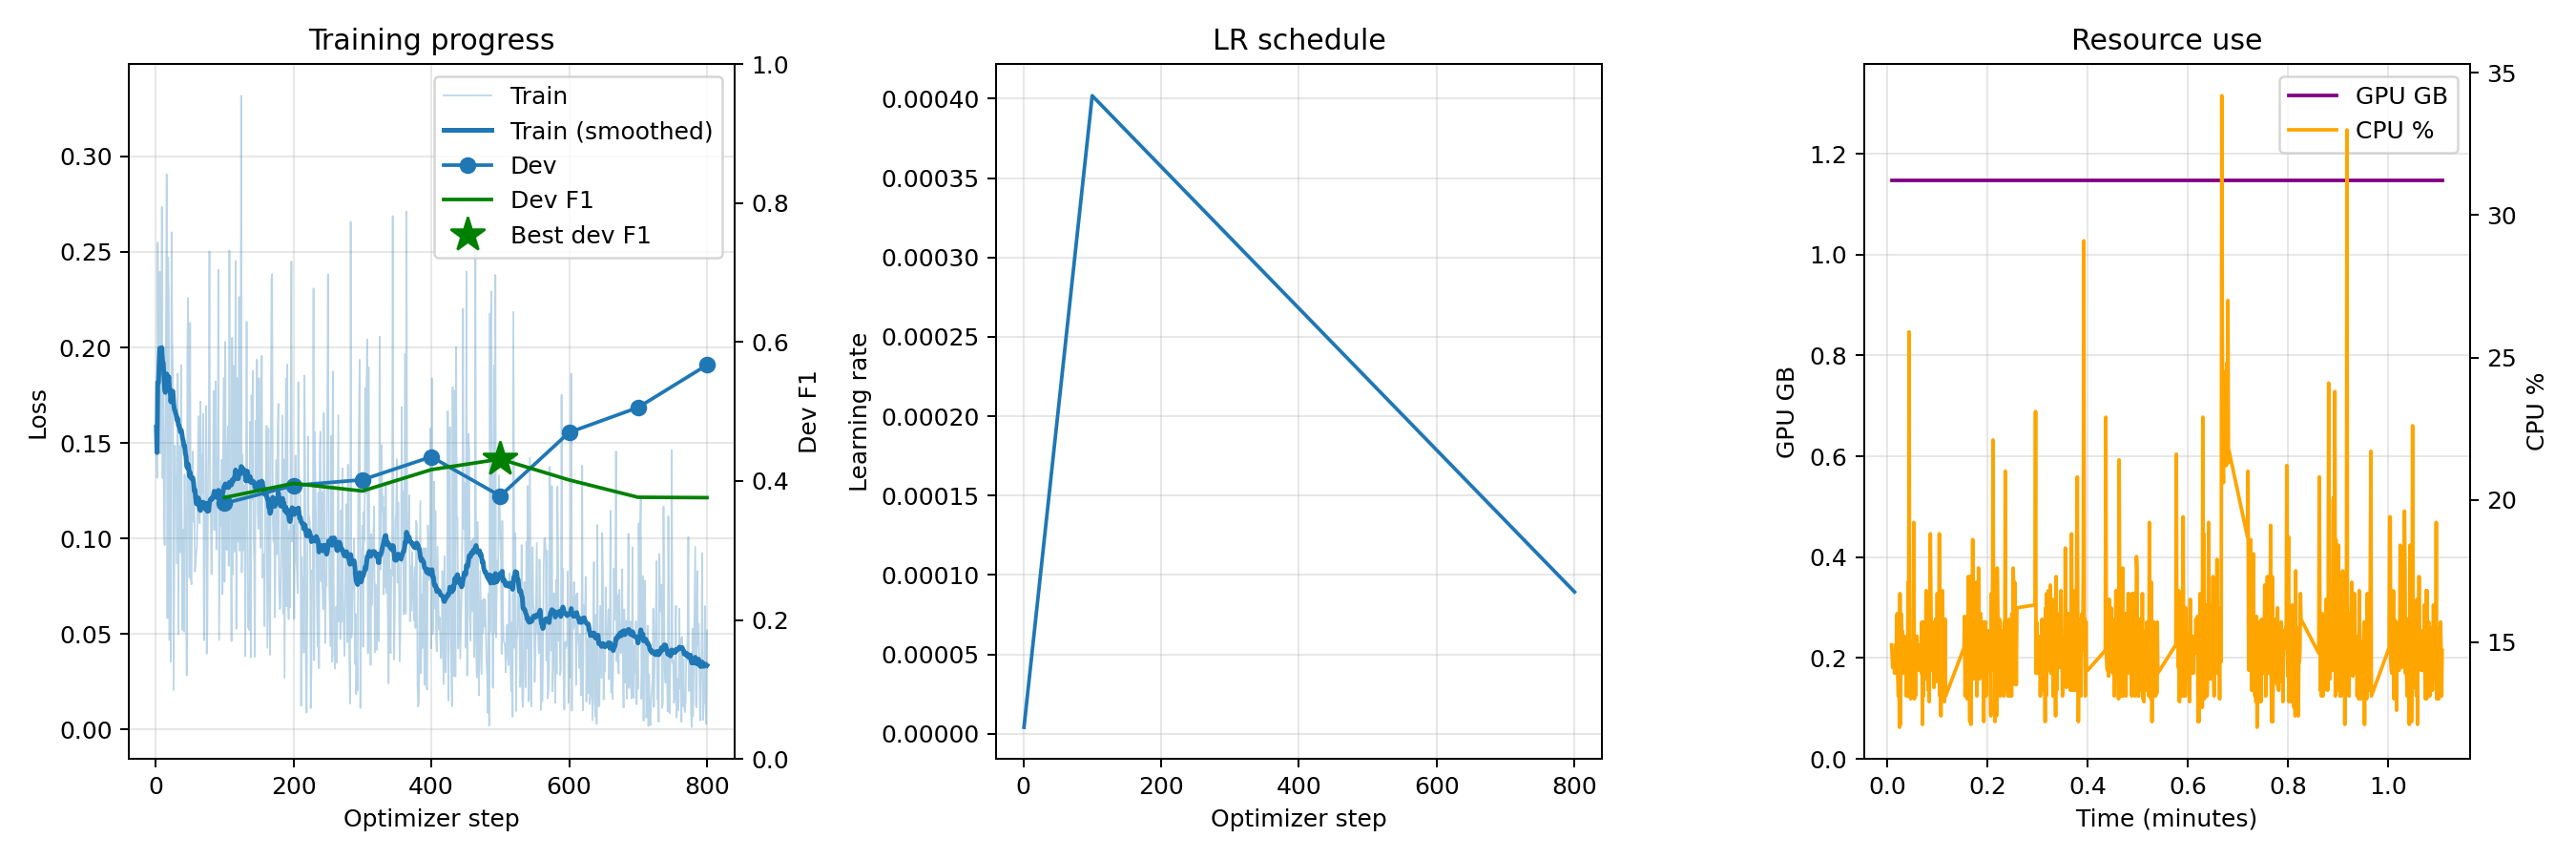

In [9]:
display(Image(filename=str(run / "plots" / "training_curves.png")))

## 7. Use the trained model

`predict` loads the adapter and runs on a GPU or a CPU:

```bash
active-gliner predict --adapter demo/run/adapter/best --task classification --labels "..." \
  --texts new.jsonl
```

In [10]:
new = [
    "Tumour cells evade T cell attack by expressing PD-L1 .",
    "The mutation increases glucose uptake and shifts metabolism to glycolysis .",
    "Samples were stored at minus 80 degrees until use .",
]
(demo / "new.jsonl").write_text("".join(json.dumps({"text": t}) + "\n" for t in new))
predictions = byod.predict(run / "adapter" / "best", TASK, labels, demo / "new.jsonl")
for text, prediction in zip(new, predictions, strict=True):
    print(text)
    print("   ", prediction["labels"])

Tumour cells evade T cell attack by expressing PD-L1 .
    []
The mutation increases glucose uptake and shifts metabolism to glycolysis .
    ['cellular energetics']
Samples were stored at minus 80 degrees until use .
    []


## What the paper found for this task

The LLM often gives a hallmark to sentences the expert marked as none, so this task needs more human labels: about three quarters of 1,000 ranked sentences.

See the paper (`paper/main.pdf`, Section 4.4) for the numbers on every dataset.